In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
!pip install -U langgraph langchain langchain-openai langchain-community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 577.1/577.1 kB 8.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 933.7/933.7 kB 22.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 47.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 23.3 MB/s  0:00:00
  Attempting uninstall: langchain-protocol
    Found existing installation: langchain-protocol 0.0.19
    Uninstalling langchain-protocol-0.0.19:
      Successfully uninstalled langchain-protocol-0.0.19
  Attempting uninstall: langsmith━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/13 [pydantic-settings]
    Found existing installation: langsmith 0.12.1━━━━━━━━━━━━━  2/13 [pydantic-settings]
    Uninstalling langsmith-0.12.1:━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/13 [pydantic-settings]
      Successfully uninstalled langsmith-0.12.1━━━━━━━━━━━━━━━━━━━  3/13 [langsmith]ngs]
  Attempting uninstall: langchain-core━━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/13 [langsmith]
    Found existing installation: langchain-core 1

In [4]:
from importlib.metadata import version

print("LangGraph:", version("langgraph"))
print("LangChain:", version("langchain"))

LangGraph: 1.2.19
LangChain: 1.4.7


In [5]:
from typing import TypedDict

class AgentState(TypedDict):
    message: str
    response: str

In [6]:
def process_message(state: AgentState):
    message = state["message"]
    response = f"Agent received: {message}"
    return {"response": response}

In [7]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)
graph_builder.add_node("process", process_message)
graph_builder.add_edge(START, "process")
graph_builder.add_edge("process", END)

graph = graph_builder.compile()

In [8]:
result = graph.invoke({
    "message": "Hello LangGraph!",
    "response": ""
})
print(result)

{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}


In [28]:
#!pip install -U langchain-google-genai

import os
from getpass import getpass
from langchain_google_genai import ChatGoogleGenerativeAI

if not os.environ.get("GOOGLE_API_KEY"):
    os.environ["GOOGLE_API_KEY"] = getpass("Enter your Google API key: ")

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",  
    max_retries=6,
    temperature=0
)

#print(llm.invoke("Say hello in one short sentence.").content)
print(llm.invoke("Say hello in one short sentence.").text)

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Hello there!


In [29]:
class AgentState(TypedDict):
    message: str
    response: str

def chatbot(state: AgentState):
    response = llm.invoke(state["message"])
    return {"response": response.text}

graph_builder = StateGraph(AgentState)
graph_builder.add_node("chatbot", chatbot)
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

graph = graph_builder.compile()

In [30]:
result = graph.invoke({
    "message": "Explain artificial intelligence in three sentences.",
    "response": ""
})
print(result["response"])

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Artificial intelligence (AI) refers to computer systems designed to perform tasks that typically require human intelligence, such as learning, reasoning, and problem-solving. These systems achieve this by processing vast amounts of data and identifying complex patterns using advanced algorithms and machine learning. Ultimately, AI aims to create technology that can autonomously adapt, make decisions, and improve its performance over time.


In [22]:
from google import genai
client = genai.Client()
for m in client.models.list():
    print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/l

In [33]:
class AgentState(TypedDict):
    question: str
    analysis: str
    answer: str

def analyze_question(state: AgentState):
    prompt = f"""
    Analyze the following question.

    Question:
    {state['question']}

    Identify:
    1. The topic
    2. The user's intention
    3. The information needed
    """
    response = llm.invoke(prompt)
    return {"analysis": response.text}

def generate_answer(state: AgentState):
    prompt = f"""
    Answer the user's question.

    Question:
    {state['question']}

    Analysis:
    {state['analysis']}

    Give a clear and technically correct answer.
    """
    response = llm.invoke(prompt)
    return {"answer": response.text}

In [34]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("analyzer", analyze_question)
graph_builder.add_node("answer", generate_answer)

graph_builder.add_edge(START, "analyzer")
graph_builder.add_edge("analyzer", "answer")
graph_builder.add_edge("answer", END)

graph = graph_builder.compile()

In [35]:
result = graph.invoke({
    "question": "What is reinforcement learning?",
    "analysis": "",
    "answer": ""
})
print(result["answer"])

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


**Reinforcement Learning (RL)** is a subfield of machine learning and artificial intelligence concerned with how an intelligent **agent** ought to take **actions** in a dynamic **environment** in order to maximize the cumulative notion of **reward**. 

Unlike supervised learning, which relies on a dataset of pre-existing correct answers (labeled data), or unsupervised learning, which looks for hidden patterns in unlabeled data, reinforcement learning is based on **learning by trial and error**. The agent discovers which actions yield the highest rewards by interacting with the environment and observing the consequences of its actions.

---

### Key Components of Reinforcement Learning

A standard reinforcement learning problem is typically modeled as a **Markov Decision Process (MDP)**, which consists of the following core elements:

1. **Agent:** The learner or decision-maker (e.g., a self-driving car algorithm, a robot arm, or a game-playing AI).
2. **Environment:** The external worl

In [36]:
class AgentState(TypedDict):
    question: str
    category: str
    answer: str

def classify_question(state: AgentState):
    prompt = f"""
    Classify this question into exactly one category:

    - mathematics
    - programming
    - artificial_intelligence

    Question:
    {state['question']}

    Return only the category.
    """
    response = llm.invoke(prompt)
    return {"category": response.text.strip().lower()}

In [37]:
def mathematics_agent(state):
    response = llm.invoke(
        f"""
        Solve this mathematics question:

        {state['question']}
        """
    )
    return {"answer": response.text}

def programming_agent(state):
    response = llm.invoke(
        f"""
        Answer this programming question.
        Include Python code when appropriate.

        {state['question']}
        """
    )
    return {"answer": response.text}

def ai_agent(state):
    response = llm.invoke(
        f"""
        Answer this artificial intelligence question
        at university level.

        {state['question']}
        """
    )
    return {"answer": response.text}

In [38]:
def route_question(state):
    category = state["category"]

    if "mathematics" in category:
        return "math"
    if "programming" in category:
        return "programming"
    return "ai"   # default / fallback branch

In [39]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("classifier", classify_question)
graph_builder.add_node("math", mathematics_agent)
graph_builder.add_node("programming", programming_agent)
graph_builder.add_node("ai", ai_agent)

graph_builder.add_edge(START, "classifier")

graph_builder.add_conditional_edges(
    "classifier",
    route_question,
    {
        "math": "math",
        "programming": "programming",
        "ai": "ai"
    }
)

graph_builder.add_edge("math", END)
graph_builder.add_edge("programming", END)
graph_builder.add_edge("ai", END)

router_graph = graph_builder.compile()

In [40]:
questions = [
    "What is the derivative of x²?",
    "How do I create a REST API with Python?",
    "What is reinforcement learning?"
]

for question in questions:
    result = router_graph.invoke({
        "question": question,
        "category": "",
        "answer": ""
    })
    print("=" * 60)
    print("QUESTION:", question)
    print("CATEGORY:", result["category"])
    print("ANSWER:", result["answer"])

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


QUESTION: What is the derivative of x²?
CATEGORY: mathematics
ANSWER: To find the derivative of $x^2$, you can use the **power rule** of calculus, which states that for any function $f(x) = x^n$, its derivative is:

$$\frac{d}{dx}(x^n) = n \cdot x^{n-1}$$

Applying this rule to $x^2$:
1. Bring the exponent ($2$) to the front.
2. Subtract $1$ from the exponent ($2 - 1 = 1$).

$$\frac{d}{dx}(x^2) = 2x^{2-1} = 2x^1 = 2x$$

Thus, the derivative of $x^2$ is **$2x$**.


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


QUESTION: How do I create a REST API with Python?
CATEGORY: programming
ANSWER: Creating a REST API in Python is very straightforward, thanks to modern web frameworks. The most popular and modern framework for this is **FastAPI** (due to its speed and automatic documentation) and **Flask** (known for its simplicity). 

Below is a guide on how to create a simple REST API using **FastAPI**.

---

### Step 1: Install FastAPI and Uvicorn
FastAPI is the framework, and Uvicorn is the ASGI server used to run the application.

Open your terminal and run:
```bash
pip install fastapi uvicorn
```

---

### Step 2: Create the API Code
Create a file named `main.py` and add the following code. This example creates a simple API that manages a list of "items".

```python
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from typing import Optional

# Initialize the FastAPI app
app = FastAPI()

# Define a Pydantic model for request validation (Data transfer object)
class Item(Ba

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


QUESTION: What is reinforcement learning?
CATEGORY: artificial_intelligence
ANSWER: At a university level, **Reinforcement Learning (RL)** is formally defined as a subfield of machine learning concerned with how an intelligent **agent** ought to take **actions** in a dynamic **environment** so as to maximize some notion of cumulative **reward**. 

Unlike supervised learning—which relies on a static dataset of labeled input-output pairs—or unsupervised learning—which seeks to find hidden structure in unlabeled data—reinforcement learning is interactive, sequential, and trial-and-error-based.

Here is a rigorous breakdown of the foundational concepts, mathematical framework, core challenges, and modern paradigms of reinforcement learning.

---

### 1. The Mathematical Framework: Markov Decision Processes (MDPs)
Formally, most RL problems are modeled as a **Markov Decision Process (MDP)**. An MDP is defined by a 5-tuple $(\mathcal{S}, \mathcal{A}, \mathcal{P}, \mathcal{R}, \gamma)$, where

In [41]:
from langchain_core.tools import tool

# --- Version from the lab (UNSAFE: do not use with untrusted input) ---
@tool
def calculator_unsafe(expression: str) -> str:
    """Calculate a mathematical expression (unsafe eval version)."""
    try:
        return str(eval(expression))
    except Exception:
        return "Invalid expression"

print(calculator_unsafe.invoke("25 * 4 + 10"))   # Expected: 110

110


In [42]:
import ast
import operator as op

_ALLOWED_OPS = {
    ast.Add: op.add, ast.Sub: op.sub, ast.Mult: op.mul, ast.Div: op.truediv,
    ast.Pow: op.pow, ast.Mod: op.mod, ast.FloorDiv: op.floordiv,
    ast.USub: op.neg, ast.UAdd: op.pos,
}

def _safe_eval(node):
    if isinstance(node, ast.Expression):
        return _safe_eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.left), _safe_eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.operand))
    raise ValueError("Unsupported expression")

@tool
def calculator(expression: str) -> str:
    """Calculate a mathematical expression such as '25 * 4 + 10'. Supports + - * / ** % //."""
    try:
        return str(_safe_eval(ast.parse(expression.strip(), mode="eval")))
    except Exception:
        return "Invalid expression"

print(calculator.invoke("25 * 4 + 10"))        # Expected: 110
print(calculator.invoke("__import__('os')"))   # Expected: Invalid expression

110
Invalid expression


In [43]:
from datetime import datetime

@tool
def current_datetime(_: str = "") -> str:
    """Return the current date and time. Use for any question about today's date or the current time."""
    return datetime.now().strftime("%A, %d %B %Y, %H:%M:%S")

print(current_datetime.invoke(""))

Saturday, 31 October 2026, 17:39:35


In [44]:
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition

tools = [calculator, current_datetime]
llm_with_tools = llm.bind_tools(tools)

def agent(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

tool_builder = StateGraph(MessagesState)
tool_builder.add_node("agent", agent)
tool_builder.add_node("tools", ToolNode(tools))

tool_builder.add_edge(START, "agent")
tool_builder.add_conditional_edges("agent", tools_condition)  # -> "tools" or END
tool_builder.add_edge("tools", "agent")                       # loop back with the result

tool_graph = tool_builder.compile()

In [45]:
for q in ["What is 125 * 38?", "What is the capital of Morocco?"]:
    result = tool_graph.invoke({"messages": [("user", q)]})
    print("=" * 60)
    print("Q:", q)
    for m in result["messages"]:
        m.pretty_print()

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Q: What is 125 * 38?
================================ Human Message =================================

What is 125 * 38?
================================== Ai Message ==================================

[]
Tool Calls:
  calculator (call_291581)
 Call ID: call_291581
  Args:
    expression: 125 * 38
================================= Tool Message =================================
Name: calculator

4750
================================== Ai Message ==================================

[{'type': 'text', 'text': '125 * 38 = 4,750', 'extras': {'signature': 'EmAKXgFpFH0TkSvx4pc7U2QLxF5kLBD80ckx7RjkiFQryygfGFEkj6AABJCAOcPLsEyjl2gTf/v+15bhDLHbj+p+VhT7TuFWFRMO+EE8l9NdZb6NRv0GA7WxY1v5WEVLgX0='}}]


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Q: What is the capital of Morocco?
================================ Human Message =================================

What is the capital of Morocco?
================================== Ai Message ==================================

[{'type': 'text', 'text': 'The capital of Morocco is **Rabat**.', 'extras': {'signature': 'EmAKXgFpFH0TbvrzM9Wg//H44kn4Ez7MFk7jqew+O1ooDVYfwFRPSVss8q4PaSh0EvC4AzGHhzuSa0WwWJRZyqjB3AfKjR6ruXg3bGTwqLtyxzlXFS3vvvvRPida0e8pVlM='}}]


In [46]:
from typing import Annotated
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list, add_messages]

def chatbot(state: ChatState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

chat_builder = StateGraph(ChatState)
chat_builder.add_node("chatbot", chatbot)
chat_builder.add_edge(START, "chatbot")
chat_builder.add_edge("chatbot", END)

In [47]:
# 1) No persistence: the agent forgets
no_memory_graph = chat_builder.compile()
no_memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]})
r = no_memory_graph.invoke({"messages": [("user", "What is my name?")]})
print("WITHOUT memory:", r["messages"][-1].content)

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


WITHOUT memory: [{'type': 'text', 'text': "I don't know your name! You haven't told me yet. What would you like me to call you?", 'extras': {'signature': 'EmAKXgFpFH0TUnStimekY429JTMT6Mt7KH+blBWYUhrmA8G4HDJhDwrVLBk8ndeE++05SuPIyzP4J4muZT8Fvw2O8OYdjshGaVai/n3+dFvGLS6940YTj3t53psLrkNzqcg='}}]


In [48]:
from langgraph.checkpoint.memory import MemorySaver

# 2) With persistence: the agent remembers within the same thread
memory_graph = chat_builder.compile(checkpointer=MemorySaver())
config = {"configurable": {"thread_id": "ahmed-1"}}

r1 = memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]}, config)
print("Agent:", r1["messages"][-1].content)

r2 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, config)
print("Agent:", r2["messages"][-1].content)

# A different thread has its own, separate memory
other = {"configurable": {"thread_id": "someone-else"}}
r3 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, other)
print("Other thread:", r3["messages"][-1].content)

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Agent: [{'type': 'text', 'text': "Hello Ahmed! It's nice to meet you. How can I help you today?", 'extras': {'signature': 'EmAKXgFpFH0TbI2SDHun7FNtC7cBu+Nqrw1eGuext+fmQQIYCWxOHc+iFW0+SEPc1AvKgq6su3eZBkbVD1MeMzO1IIPkL5YgJir5kkz3ZgBBbRd63v+GioyJRJWzBozWENY='}}]


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Agent: [{'type': 'text', 'text': 'Your name is Ahmed.', 'extras': {'signature': 'EmAKXgFpFH0TAZZjDjacCugbZue9qcQdkNUTxobGBjzkbRVlBGvSIFnJ0ysbA885MuWAwcth28joKxU7LY57YSR10NvCkc8/Ejg86T8xv155kcZgAeeO2cVYqdg11rev4TI='}}]


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Other thread: [{'type': 'text', 'text': "I don't know your name, as we haven't been introduced! What would you like me to call you?", 'extras': {'signature': 'EmAKXgFpFH0TU52uiyHLvQI86lLf6PlpzIdILlwse4QWGqtJzmZh0SRmNH6BcASvDbOecvbJ1WFWDQVghk0+wYX4cl/yn4GIFAiVwn2BGlCblCdz+KuD7Ha20CmpjZCJucA='}}]


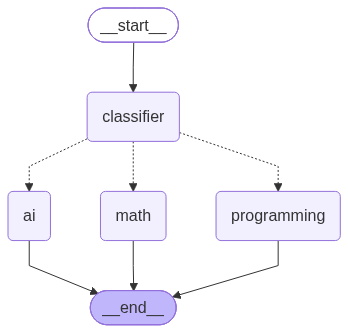

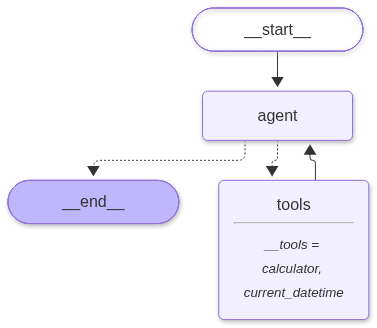

In [49]:
from IPython.display import Image, display

def show_graph(g):
    try:
        display(Image(g.get_graph().draw_mermaid_png()))
    except Exception as e:
        print("PNG rendering unavailable:", e)
        print(g.get_graph().draw_mermaid())

show_graph(router_graph)
show_graph(tool_graph)

In [50]:
import time

test_cases = [
    ("What is the derivative of x²?", "mathematics"),
    ("Solve 2x + 3 = 11", "mathematics"),
    ("How do I reverse a list in Python?", "programming"),
    ("Write a function to check for palindromes.", "programming"),
    ("What is a convolutional neural network?", "artificial_intelligence"),
    ("Explain overfitting.", "artificial_intelligence"),
]

correct, rows = 0, []
for q, expected in test_cases:
    t0 = time.time()
    out = router_graph.invoke({"question": q, "category": "", "answer": ""})
    got = out["category"]
    ok = expected in got
    correct += ok
    rows.append((q, expected, got, ok, round(time.time() - t0, 2)))

import pandas as pd
df = pd.DataFrame(rows, columns=["question", "expected", "got", "correct", "seconds"])
display(df)
print(f"Routing accuracy: {correct}/{len(test_cases)} = {correct/len(test_cases):.0%}")

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_

,question,expected,got,correct,seconds
0,What is the derivative of x²?,mathematics,mathematics,True,1.25
1,Solve 2x + 3 = 11,mathematics,mathematics,True,1.12
2,How do I reverse a list in Python?,programming,programming,True,2.26
3,Write a function to check for palindromes.,programming,programming,True,1.98
4,What is a convolutional neural network?,artificial_intelligence,artificial_intelligence,True,4.79
5,Explain overfitting.,artificial_intelligence,artificial_intelligence,True,4.06


Routing accuracy: 6/6 = 100%


In [51]:
from langchain_core.messages import SystemMessage, AIMessage, HumanMessage

CATEGORIES = ["COURSES", "PROGRAMMING", "MATHEMATICS", "ADMINISTRATION", "GENERAL"]

class AssistantState(TypedDict):
    messages: Annotated[list, add_messages]
    category: str

In [52]:
def classify(state: AssistantState):
    last = state["messages"][-1]
    text = (last.content if hasattr(last, "content") else str(last)).strip()

    # Error handling: empty question
    if not text:
        return {"category": "EMPTY"}

    prompt = f"""
    Classify the student's question into exactly one category:
    COURSES (course content, syllabus, schedules, exams, grading),
    PROGRAMMING, MATHEMATICS,
    ADMINISTRATION (enrollment, fees, certificates, procedures, deadlines),
    GENERAL (anything else).

    Question: {text}

    Return only the category name.
    """
    try:
        raw = llm.invoke(prompt).content.strip().upper()
    except Exception as e:                      # Error handling: API errors
        print("Classifier API error:", e)
        return {"category": "ERROR"}

    # Error handling: unknown/unexpected label -> GENERAL
    category = next((c for c in CATEGORIES if c in raw), "GENERAL")
    return {"category": category}

In [53]:
SYSTEM_PROMPTS = {
    "COURSES": "You are a university courses advisor. Explain course content, prerequisites, "
               "schedules and study strategies. If you lack institution-specific data, say so honestly.",
    "PROGRAMMING": "You are a programming tutor. Give clear explanations and correct Python code when appropriate.",
    "MATHEMATICS": "You are a mathematics tutor. Show steps. ALWAYS use the calculator tool for arithmetic.",
    "ADMINISTRATION": "You are a university administration assistant (enrollment, fees, certificates, procedures). "
                      "Never invent official rules or deadlines; recommend contacting the administration office when unsure.",
    "GENERAL": "You are a helpful university assistant. Use the date/time tool for questions about the current date or time.",
}

def make_agent(category: str):
    system = SystemMessage(content=SYSTEM_PROMPTS[category])

    def node(state: AssistantState):
        try:
            response = llm_with_tools.invoke([system] + state["messages"])
            return {"messages": [response]}
        except Exception as e:                  # Error handling: API errors
            return {"messages": [AIMessage(
                content=f"Sorry, I ran into a technical problem while answering ({type(e).__name__}). Please try again."
            )]}
    return node

def fallback(state: AssistantState):
    if state["category"] == "EMPTY":
        msg = "Your question seems to be empty. Please type a question and I'll help."
    else:
        msg = "Sorry, I couldn't process your question right now. Please try again in a moment."
    return {"messages": [AIMessage(content=msg)]}

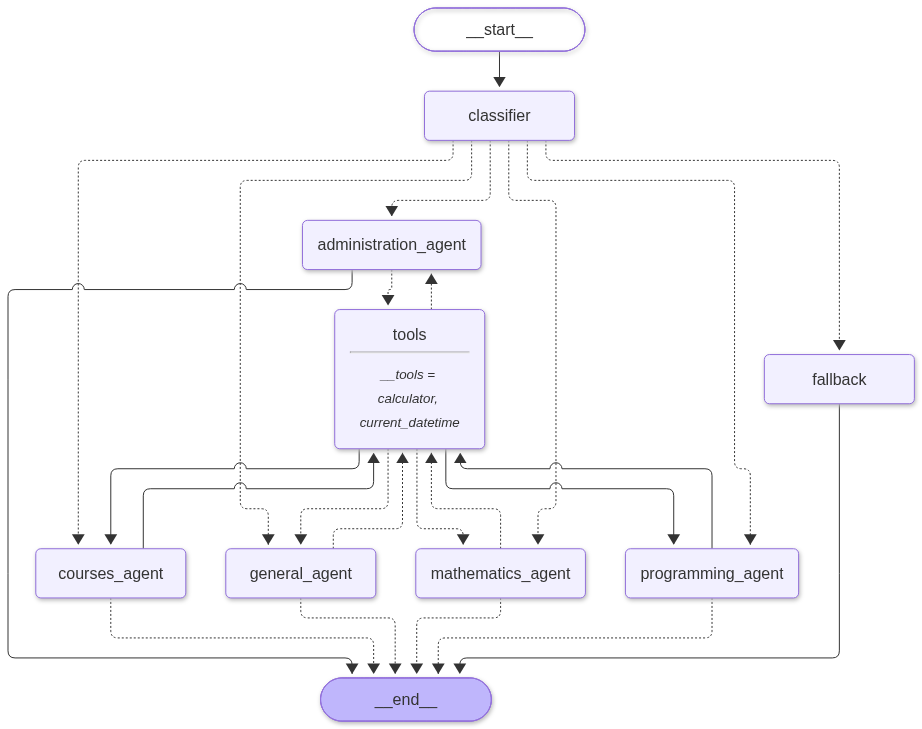

In [54]:
NODE_NAMES = {c: f"{c.lower()}_agent" for c in CATEGORIES}

def route_after_classifier(state: AssistantState):
    return NODE_NAMES.get(state["category"], "fallback")

def route_after_agent(state: AssistantState):
    last = state["messages"][-1]
    return "tools" if getattr(last, "tool_calls", None) else END

def route_after_tools(state: AssistantState):
    # return to the agent that requested the tool
    return NODE_NAMES.get(state["category"], "general_agent")

builder = StateGraph(AssistantState)
builder.add_node("classifier", classify)
builder.add_node("fallback", fallback)
builder.add_node("tools", ToolNode(tools, handle_tool_errors=True))
for c in CATEGORIES:
    builder.add_node(NODE_NAMES[c], make_agent(c))

builder.add_edge(START, "classifier")
builder.add_conditional_edges(
    "classifier", route_after_classifier,
    {**{n: n for n in NODE_NAMES.values()}, "fallback": "fallback"},
)
for c in CATEGORIES:
    builder.add_conditional_edges(NODE_NAMES[c], route_after_agent, {"tools": "tools", END: END})
builder.add_conditional_edges("tools", route_after_tools, {n: n for n in NODE_NAMES.values()})
builder.add_edge("fallback", END)

assistant = builder.compile(checkpointer=MemorySaver())
show_graph(assistant)

In [55]:
def ask(question: str, thread_id: str = "demo"):
    config = {"configurable": {"thread_id": thread_id}}
    result = assistant.invoke({"messages": [HumanMessage(content=question)]}, config)
    print("=" * 70)
    print("USER    :", question)
    print("CATEGORY:", result["category"])
    print("ASSISTANT:", result["messages"][-1].content)
    return result

demo_queries = [
    "What topics are usually covered in a machine learning course?",     # COURSES
    "Write a Python function that computes the factorial of n.",         # PROGRAMMING
    "What is 125 * 38 + 17?",                                            # MATHEMATICS (calculator)
    "How do I request an enrollment certificate?",                       # ADMINISTRATION
    "What is today's date?",                                             # GENERAL (date/time tool)
    "   ",                                                               # Error: empty question
]
for q in demo_queries:
    ask(q)

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Classifier API error: 'list' object has no attribute 'strip'
USER    : What topics are usually covered in a machine learning course?
CATEGORY: ERROR
ASSISTANT: Sorry, I couldn't process your question right now. Please try again in a moment.


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Classifier API error: 'list' object has no attribute 'strip'
USER    : Write a Python function that computes the factorial of n.
CATEGORY: ERROR
ASSISTANT: Sorry, I couldn't process your question right now. Please try again in a moment.


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Classifier API error: 'list' object has no attribute 'strip'
USER    : What is 125 * 38 + 17?
CATEGORY: ERROR
ASSISTANT: Sorry, I couldn't process your question right now. Please try again in a moment.


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Classifier API error: 'list' object has no attribute 'strip'
USER    : How do I request an enrollment certificate?
CATEGORY: ERROR
ASSISTANT: Sorry, I couldn't process your question right now. Please try again in a moment.


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Classifier API error: 'list' object has no attribute 'strip'
USER    : What is today's date?
CATEGORY: ERROR
ASSISTANT: Sorry, I couldn't process your question right now. Please try again in a moment.
USER    :    
CATEGORY: EMPTY
ASSISTANT: Your question seems to be empty. Please type a question and I'll help.


In [56]:
# Memory test: same thread_id
ask("My name is Ahmed.", thread_id="memory-test")
ask("What is my name?", thread_id="memory-test");

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Classifier API error: 'list' object has no attribute 'strip'
USER    : My name is Ahmed.
CATEGORY: ERROR
ASSISTANT: Sorry, I couldn't process your question right now. Please try again in a moment.


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Classifier API error: 'list' object has no attribute 'strip'
USER    : What is my name?
CATEGORY: ERROR
ASSISTANT: Sorry, I couldn't process your question right now. Please try again in a moment.


In [57]:
# Inspect the full message trace (including tool calls) of one run
r = assistant.invoke(
    {"messages": [HumanMessage(content="Compute (15 + 27) * 3 using the calculator.")]},
    {"configurable": {"thread_id": "trace"}},
)
for m in r["messages"]:
    m.pretty_print()

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Classifier API error: 'list' object has no attribute 'strip'
================================ Human Message =================================

Compute (15 + 27) * 3 using the calculator.
================================== Ai Message ==================================

Sorry, I couldn't process your question right now. Please try again in a moment.


In [ ]:

1. **Node** : fonction Python qui reçoit l'état et retourne une mise à jour partielle de cet état.
2. **Edge** : transition qui définit quel nœud s'exécute ensuite (fixe, ou conditionnelle).
3. **START** : nœud virtuel, point d'entrée du graphe.
4. **END** : nœud virtuel, point de sortie ; le graphe s'arrête et renvoie l'état final.
5. **Pourquoi passer l'état ?** Les nœuds sont indépendants : l'état est leur canal de communication commun. Il conserve le contexte, rend le flux traçable et testable, et permet la persistance et le routage conditionnel.

In [ ]:
## Conclusion
- Un graphe LangGraph rend le flux **explicite** : state partagé, routage conditionnel, boucle agent <-> outils, persistance par thread.
- Limites : classification par LLM (une requête de plus, erreurs possibles), dépendance à une API externe (quotas, 503), pas de vraies données institutionnelles pour COURSES/ADMINISTRATION.
- Améliorations : RAG sur les documents de l'établissement, sorties structurées pour le classifieur, `RetryPolicy`, checkpointer persistant (SQLite/Postgres), évaluation sur un jeu plus large.